# Anthony — hyperparameter experiments

Ten runs, varying gamma, with the target-sync interval as the secondary.

Every run uses the same environment and the same step budget as the
other two members, or the results cannot be compared. Record each row in
`AnthonyHyperparameter_experiment_results.md` as the run finishes, not at
the end.

Models go in `models/`, CSV logs in `logs/`, plots in `plots/`, all next
to this notebook. Never overwrite a previous run.

## Setup

In [1]:
import os
os.environ["UV_LINK_MODE"] = "copy"

import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = Path("/kaggle").exists()

if IN_COLAB:
    ROOT = Path("/content/dqn-atari")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-b", "Anthony", "https://github.com/H-levison/dqn-atari.git", str(ROOT)], check=True)
    subprocess.run("curl -LsSf https://astral.sh/uv/install.sh | sh", shell=True, check=True)
    os.environ["PATH"] = str(Path.home() / ".local/bin") + os.pathsep + os.environ["PATH"]

elif IN_KAGGLE:
    ROOT = Path("/kaggle/working/dqn-atari")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-b", "Anthony", "https://github.com/H-levison/dqn-atari.git", str(ROOT)], check=True)

else:
    found = Path.cwd()
    while not (found / "train.py").exists() and found != found.parent:
        found = found.parent
    if not (found / "train.py").exists():
        raise RuntimeError("Could not find train.py by walking up from this notebook's folder.")
    ROOT = found

print("Project folder:", ROOT)

subprocess.run(["uv", "sync"], cwd=ROOT, check=True)

Cloning into '/kaggle/working/dqn-atari'...


Project folder: /kaggle/working/dqn-atari


Using CPython 3.13.16 interpreter at: /usr/bin/python3
Creating virtual environment at: .venv
Resolved 100 packages in 72ms
Prepared 71 packages in 3m 05s
Installed 71 packages in 14.53s
 + ale-py==0.12.1
 + asttokens==3.0.2
 + cloudpickle==3.1.2
 + comm==0.2.3
 + contourpy==1.4.0
 + cuda-bindings==12.9.10
 + cuda-pathfinder==1.8.6
 + cuda-toolkit==12.6.3
 + cycler==0.12.1
 + debugpy==1.8.22
 + executing==2.3.0
 + farama-notifications==0.0.6
 + filelock==4.2.9
 + fonttools==4.68.0
 + fsspec==2026.9.0
 + gymnasium==1.4.0
 + ipykernel==7.4.0
 + ipython==9.18.1
 + ipython-pygments-lexers==1.1.1
 + jedi==0.20.1
 + jinja2==3.1.6
 + jupyter-client==8.10.0
 + jupyter-core==5.9.1
 + kiwisolver==1.5.1
 + markupsafe==3.0.4
 + matplotlib==3.11.2
 + matplotlib-inline==0.2.2
 + mpmath==1.3.0
 + nest-asyncio2==1.7.4
 + networkx==3.7
 + numpy==2.5.4
 + nvidia-cublas-cu12==12.6.4.1
 + nvidia-cuda-cupti-cu12==12.6.80
 + nvidia-cuda-nvrtc-cu12==12.6.85
 + nvidia-cuda-runtime-cu12==12.6.77
 + nvidia-cudn

CompletedProcess(args=['uv', 'sync'], returncode=0)

In [2]:
import sys
import pandas as pd

sys.path.insert(0, str(ROOT))
from plot_results import plot_training

folder = ROOT / "experiments" / "Anthony" / "exp01"
log_path = folder / "log.csv"

if not log_path.exists():
    print(f"No log.csv yet at {log_path} — run_experiment(1, ...) hasn't finished (or started).")
else:
    log = pd.read_csv(log_path)
    fig = plot_training(log, title="exp01: gamma=0.90, batch_size=16")
    fig.savefig(folder / "log.png", dpi=120)

No log.csv yet at /kaggle/working/dqn-atari/experiments/Anthony/exp01/log.csv — run_experiment(1, ...) hasn't finished (or started).


In [3]:
print("Project folder:", ROOT)
print("train.py found:", (ROOT / "train.py").exists())

Project folder: /kaggle/working/dqn-atari
train.py found: True


In [7]:
import time
import pandas as pd
from plot_results import plot_training

def run_experiment(number, gamma, batch_size):
    folder = ROOT / "experiments" / "Anthony" / f"exp{number:02d}"
    log_path = folder / "log.csv"

    command = [
        "uv", "run", "train.py",
        "--lr", "1e-4",
        "--gamma", str(gamma),
        "--batch-size", str(batch_size),
        "--eps-start", "1.0",
        "--eps-end", "0.01",
        "--eps-decay", "200000",
        "--out", str(folder),
    ]

    print("Starting experiment", number)
    start_time = time.time()

    subprocess.run(command, cwd=ROOT, check=True)

    minutes = (time.time() - start_time) / 60
    print(f"Experiment {number} finished in {minutes:.1f} minutes")

    log = pd.read_csv(log_path)
    fig = plot_training(log, title=f"exp{number:02d}: gamma={gamma}, batch_size={batch_size}")
    fig.savefig(folder / "log.png", dpi=120)

## Runs

One cell per experiment. Copy the cell, change the hyperparameters, and
keep the output in the committed notebook as evidence that it ran.

In [9]:
subprocess.run(["uv", "add", "wrapt"], cwd=ROOT, check=True)

Resolved 101 packages in 2ms
Checked 47 packages in 0.80ms


CompletedProcess(args=['uv', 'add', 'wrapt'], returncode=0)

Starting experiment 1


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Experiment 1 finished in 15.2 minutes


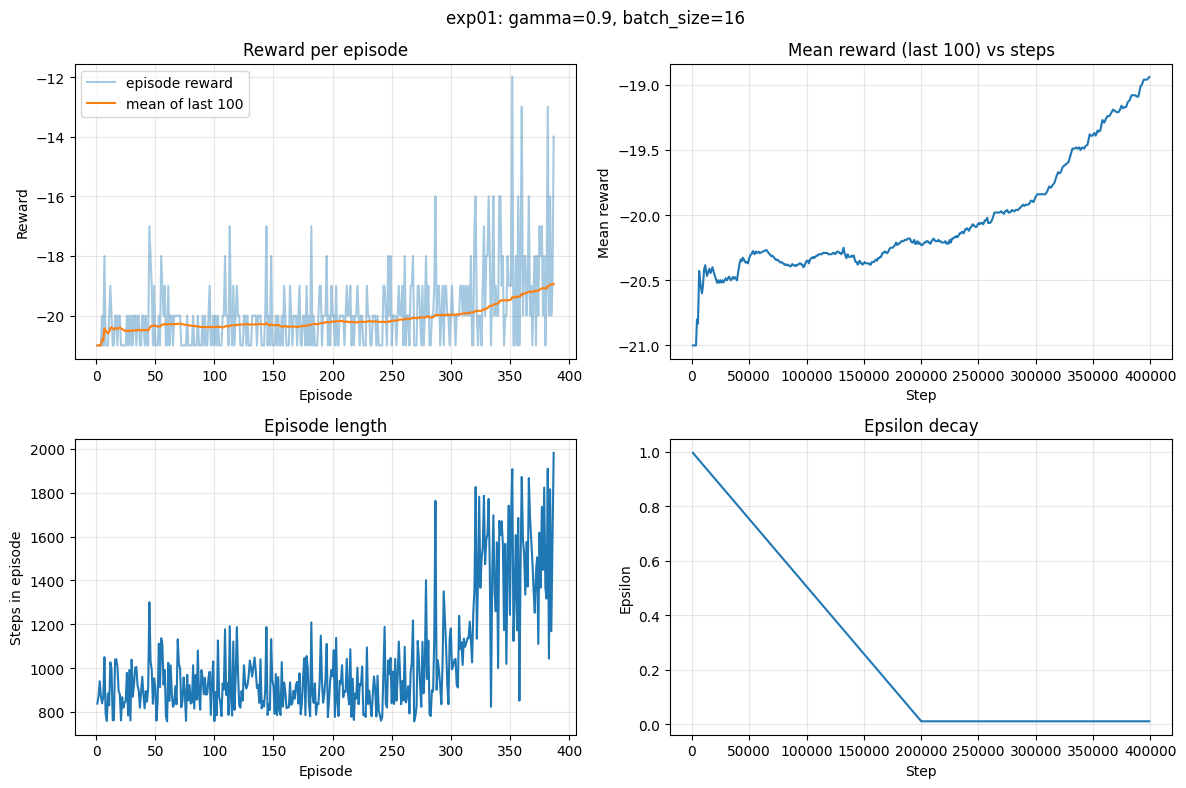

In [10]:
# Experiment 1
run_experiment(1, 0.90, 16)

Starting experiment 2


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Experiment 2 finished in 16.0 minutes


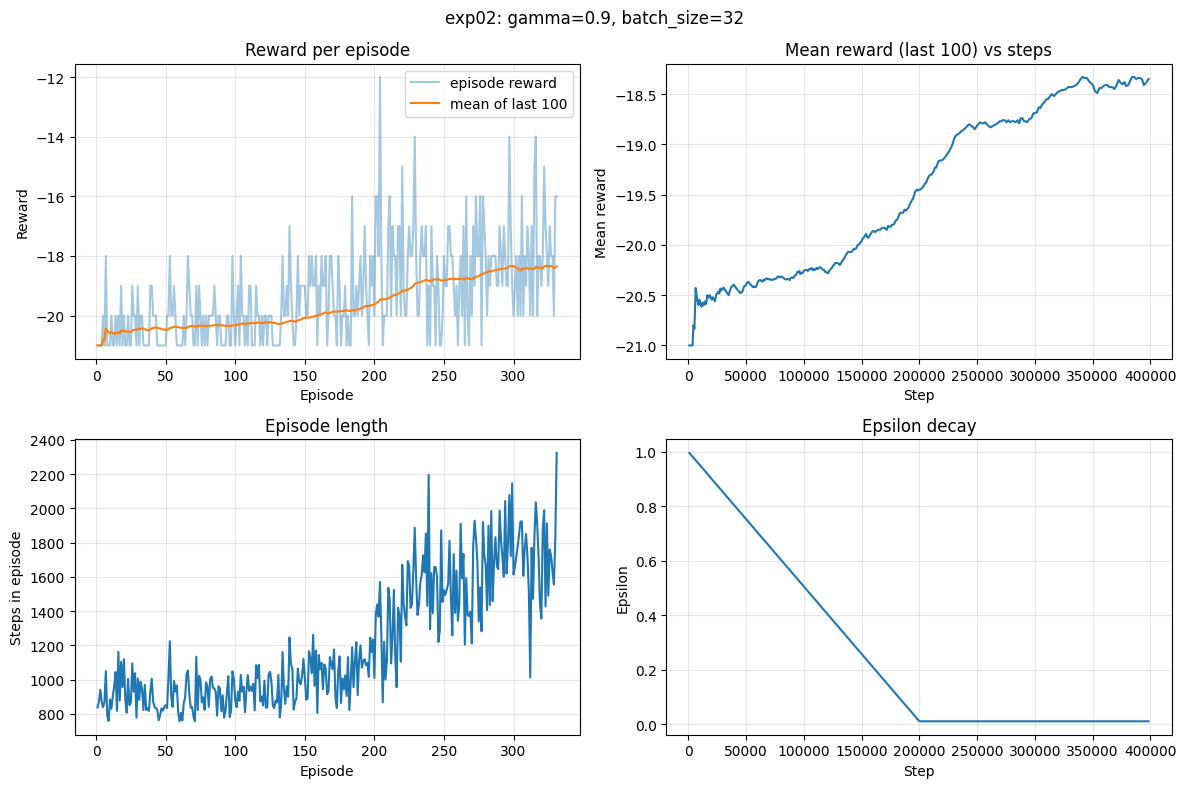

In [11]:
# Experiment 2
run_experiment(2, 0.90, 32)

Starting experiment 3


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Experiment 3 finished in 17.0 minutes


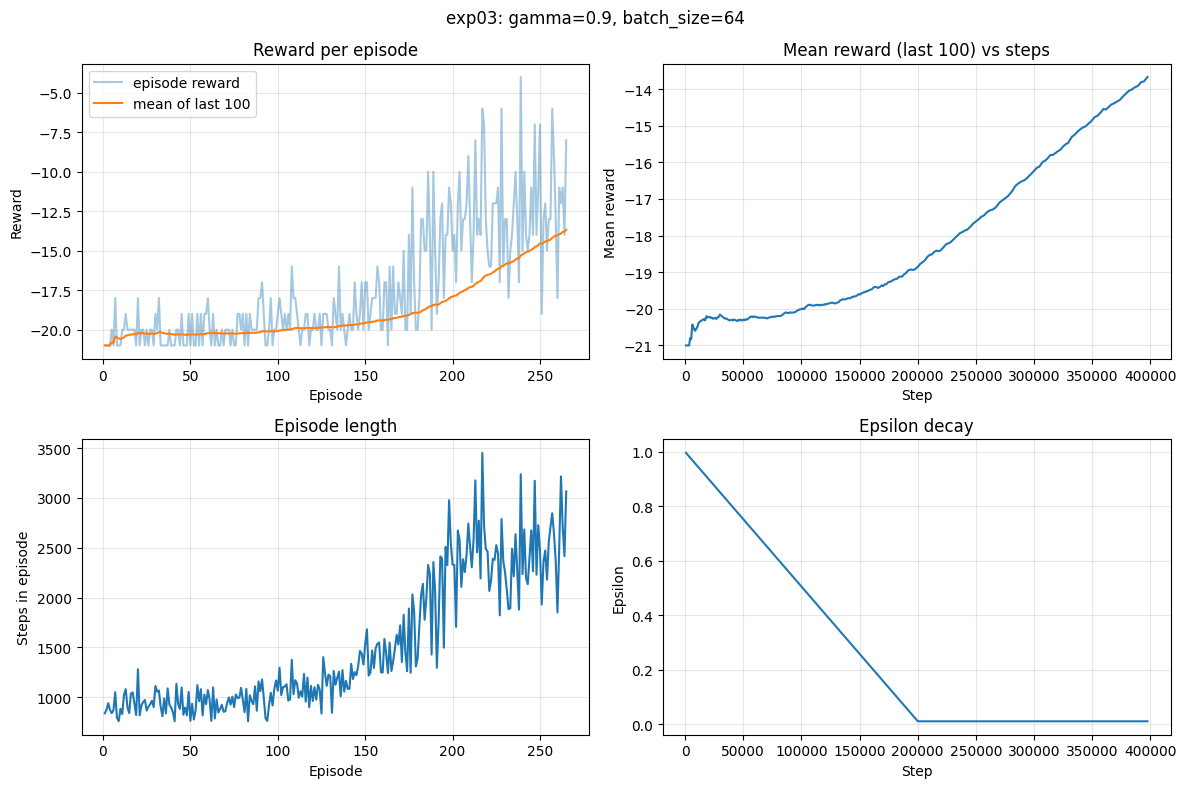

In [13]:
# Experiment 3
run_experiment(3, 0.90, 64)

Starting experiment 4


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Experiment 4 finished in 15.5 minutes


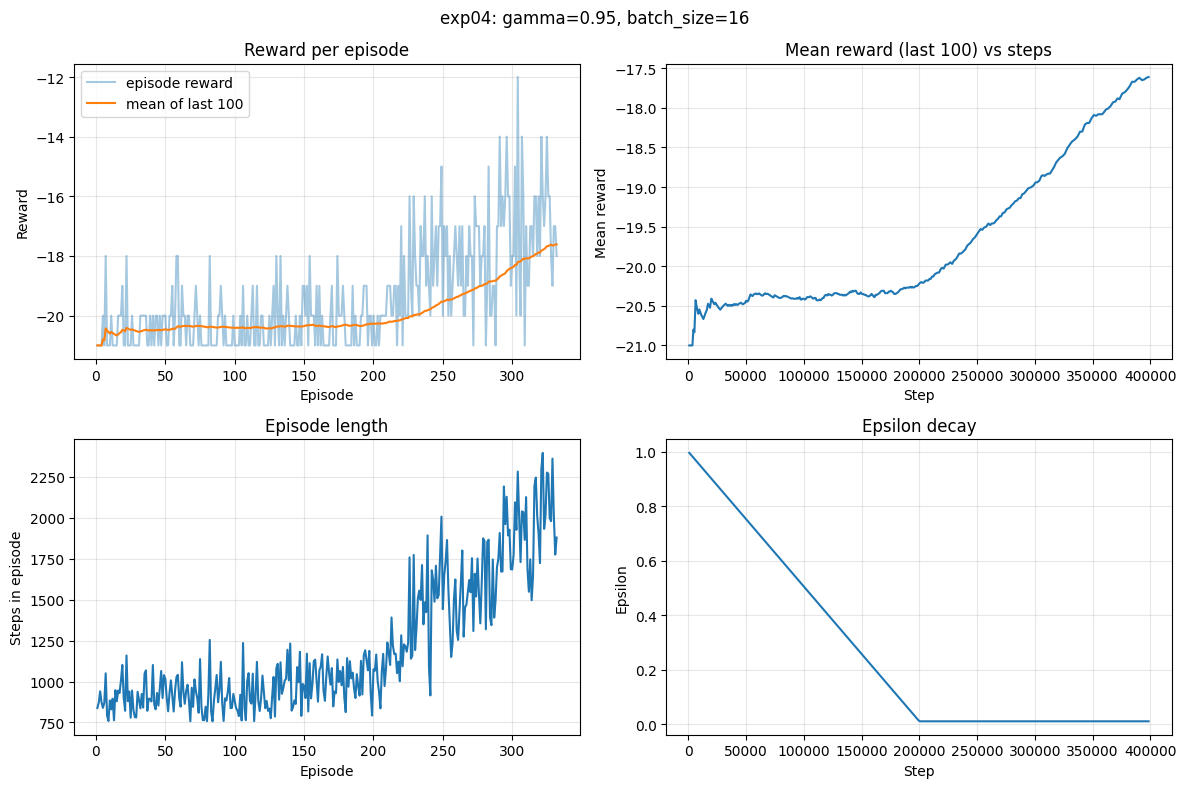

In [14]:
# Experiment 4
run_experiment(4, 0.95, 16)

Starting experiment 5


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Experiment 5 finished in 16.1 minutes


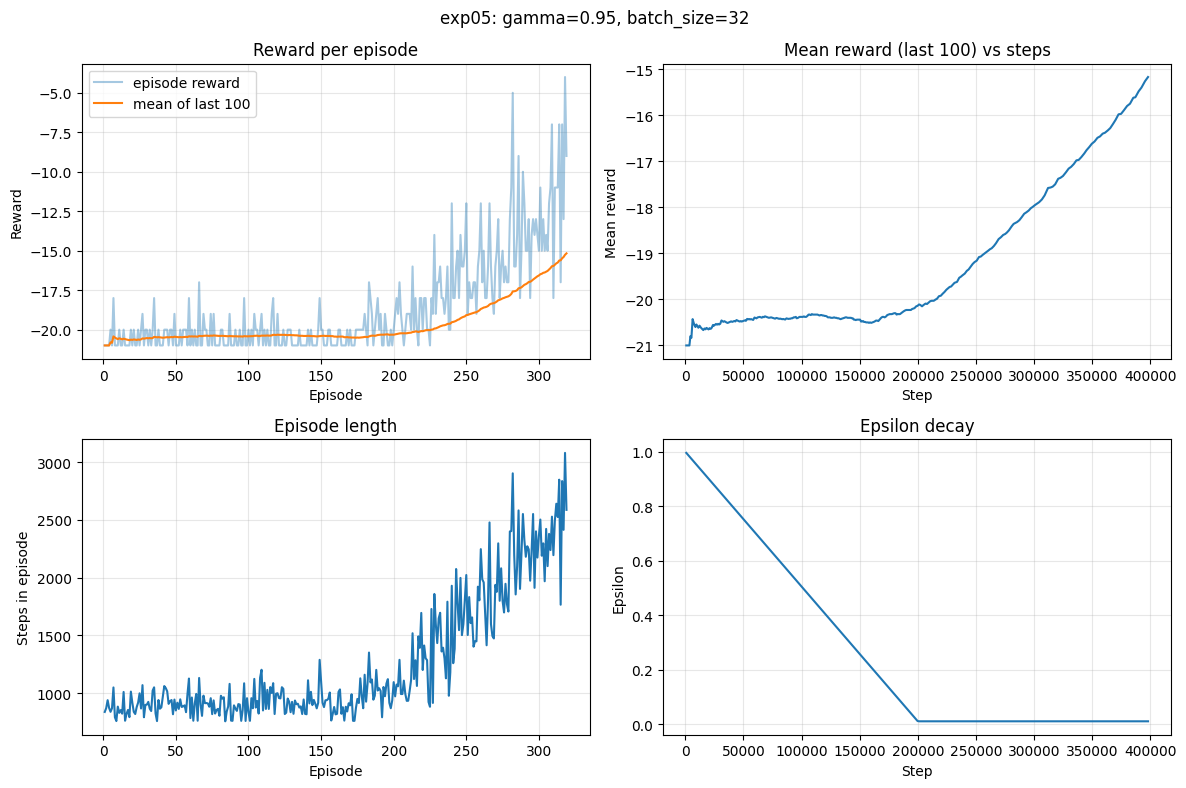

In [15]:
# Experiment 5
run_experiment(5, 0.95, 32)

Starting experiment 6


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Experiment 6 finished in 17.2 minutes


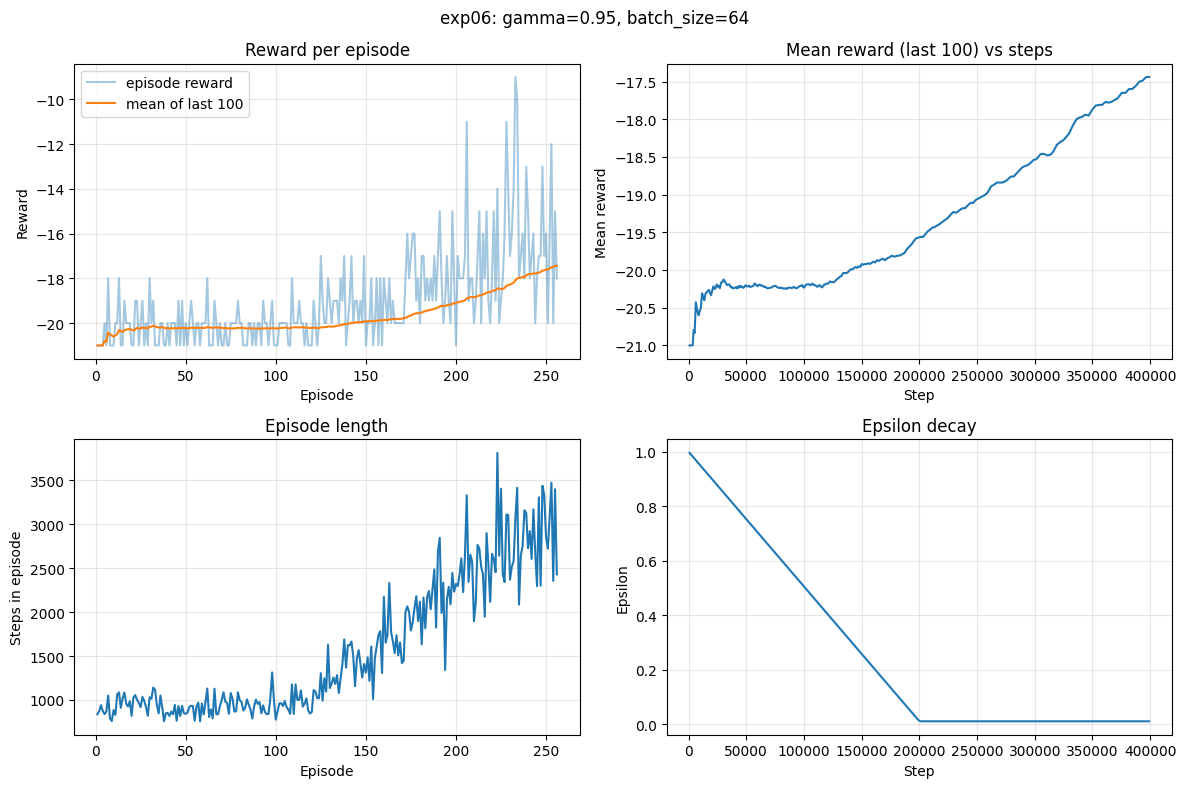

In [16]:
# Experiment 6
run_experiment(6, 0.95, 64)

Starting experiment 7


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Experiment 7 finished in 15.3 minutes


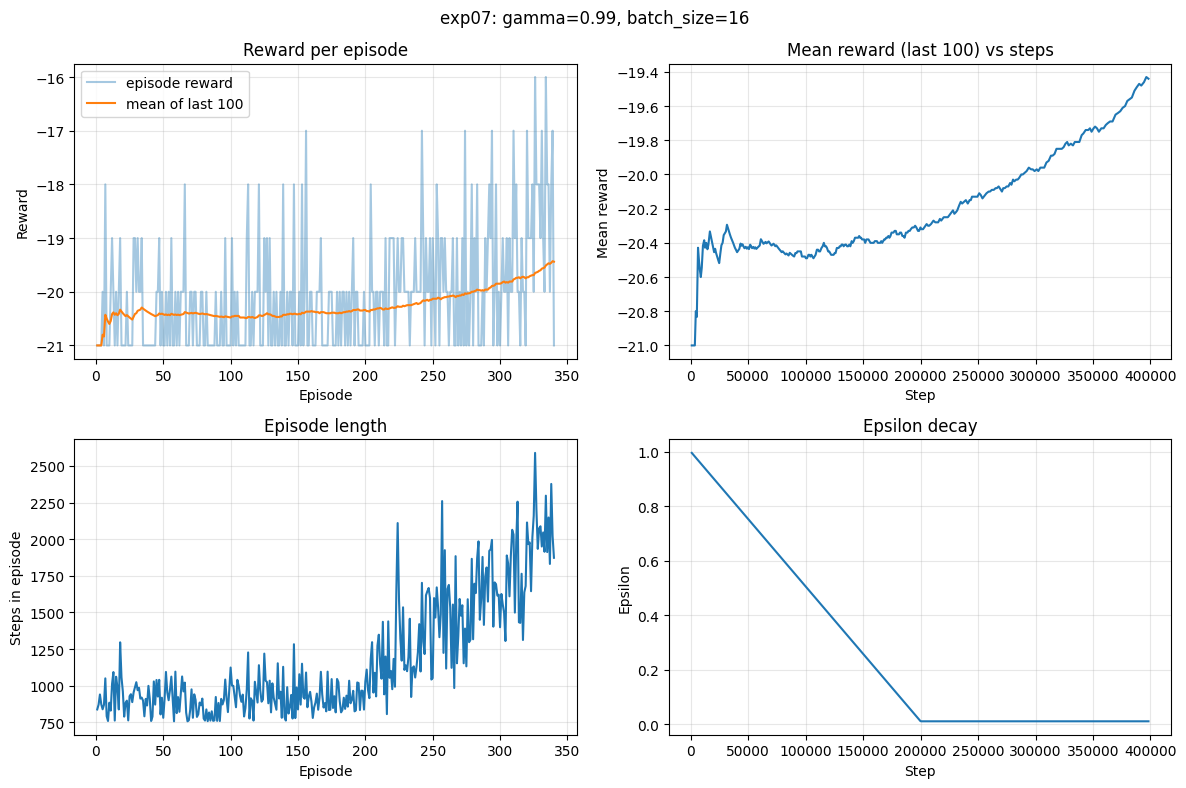

In [17]:
# Experiment 7
run_experiment(7, 0.99, 16)

Starting experiment 8


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Experiment 8 finished in 16.1 minutes


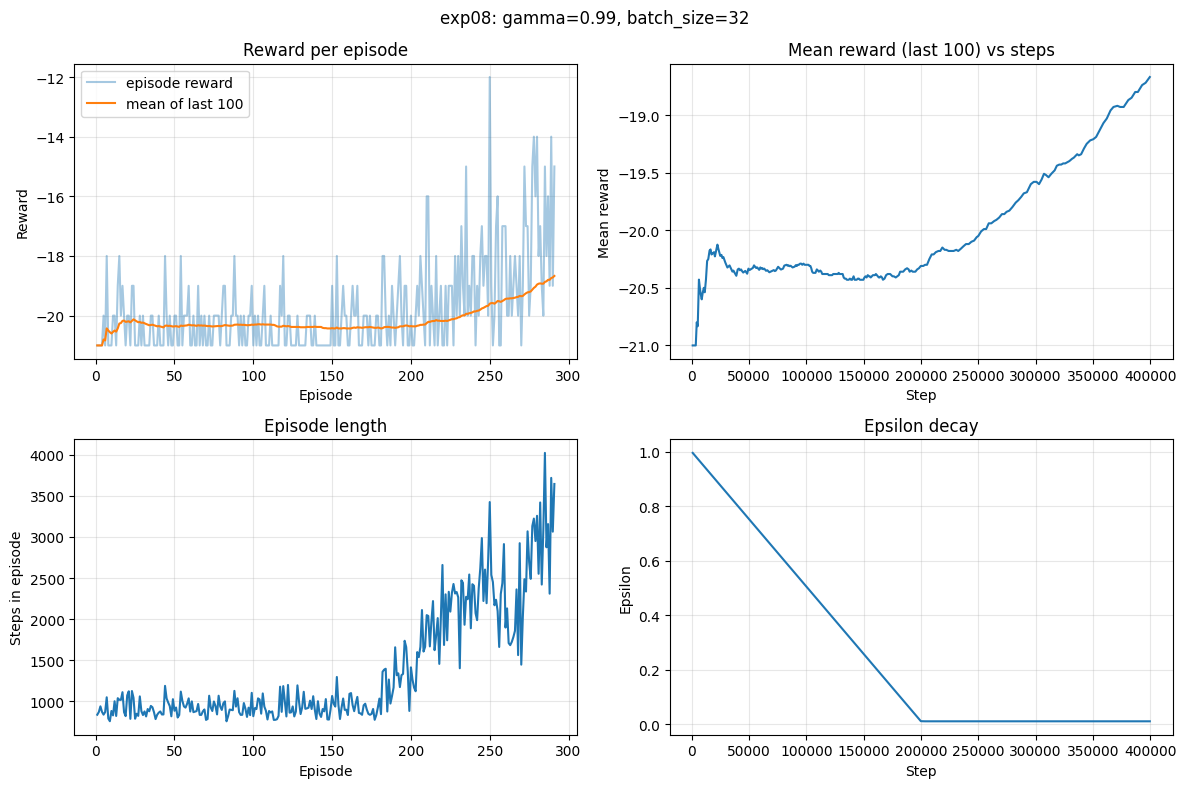

In [18]:
# Experiment 8
run_experiment(8, 0.99, 32)

Starting experiment 9


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Experiment 9 finished in 17.0 minutes


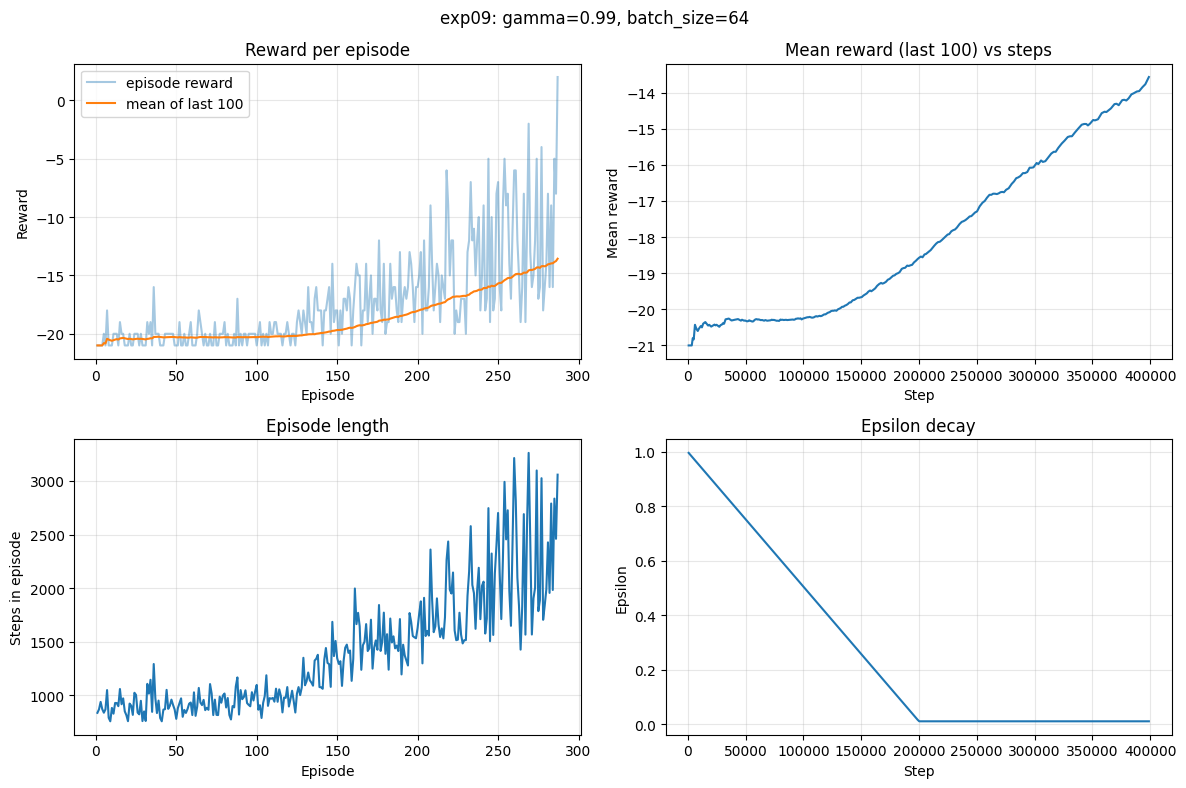

In [19]:
# Experiment 9
run_experiment(9, 0.99, 64)

Starting experiment 10


A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Experiment 10 finished in 16.0 minutes


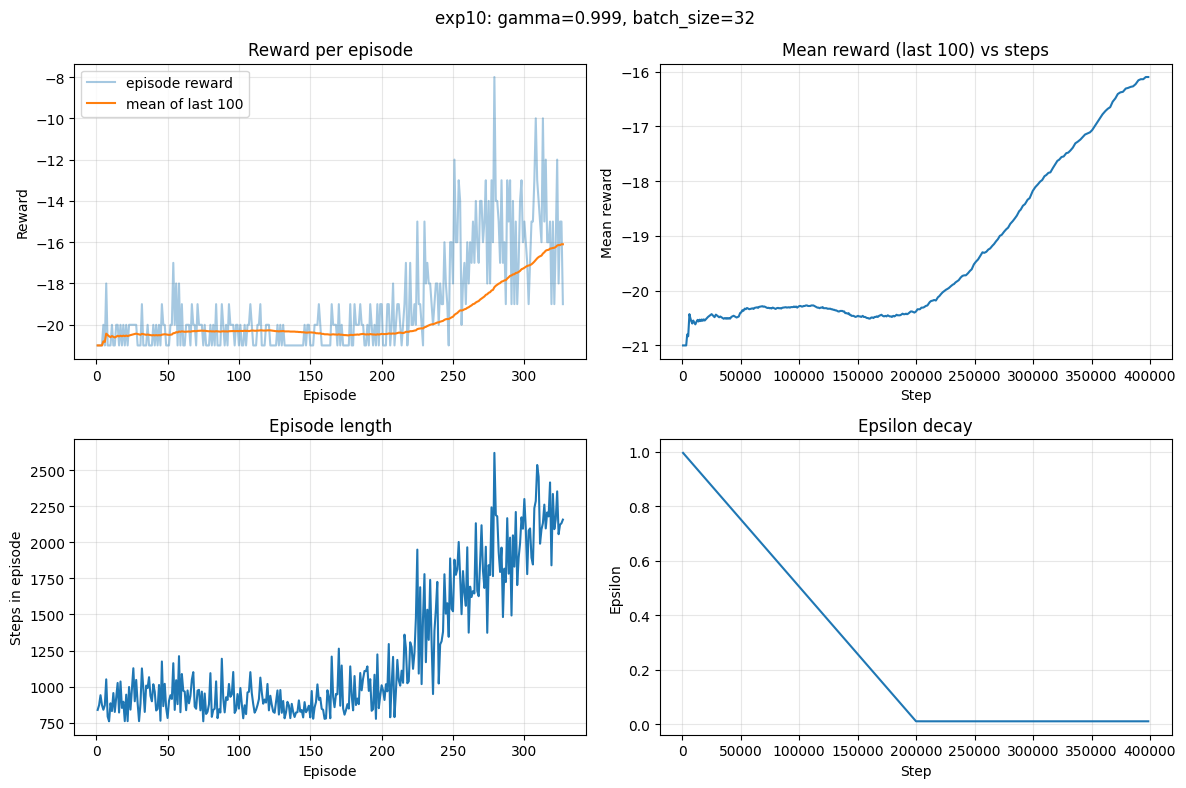

In [20]:
# Experiment 10
run_experiment(10, 0.999, 32)

The values that stay the same in every run:

```
learning rate: 1e-4
epsilon start: 1.0
epsilon end: 0.01
epsilon decay: 200000
target-sync: 1000 (the default)
```

The values being tested: gamma and batch size.

Each run saves to its own folder: `experiments/Anthony/exp01/` ... `exp10/`.


## What I found

Best and worst configuration, and which hyperparameter caused it.
This is the 2 minutes you present.